# Libraries and Configuration

In [1]:
import os
import random
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from transformers import logging
logging.set_verbosity_error()

from src.dataset import create_datasets
from src.model import MiniVLA
from src.train import train_model
from src.evaluate import evaluate_model
from src.inference import run_inference


# Configuration

DATA_DIR = "libero_spatial_no_noops/1.0.0"
IMAGE_SIZE = 224
TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1
SEED = 42

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


# Data Loading

In [2]:
train_dataset, val_dataset, test_dataset = create_datasets(
    DATA_DIR,
    train_ratio=TRAIN_RATIO,
    val_ratio=VAL_RATIO,
    test_ratio=TEST_RATIO,
    image_size=IMAGE_SIZE,
    use_wrist_image=False,
    seed=SEED,
)

Found 16 TFRecord files.
Loaded 432 episodes.
Total timesteps: 52970

Episode-level split:
Train: 345 episodes
Val:   43 episodes
Test:  44 episodes
Created dataset: 345 episodes, 41935 timesteps
Augmentation: ON
Created dataset: 43 episodes, 5505 timesteps
Augmentation: OFF
Created dataset: 44 episodes, 5530 timesteps
Augmentation: OFF


#  Dataset Sample Visualization

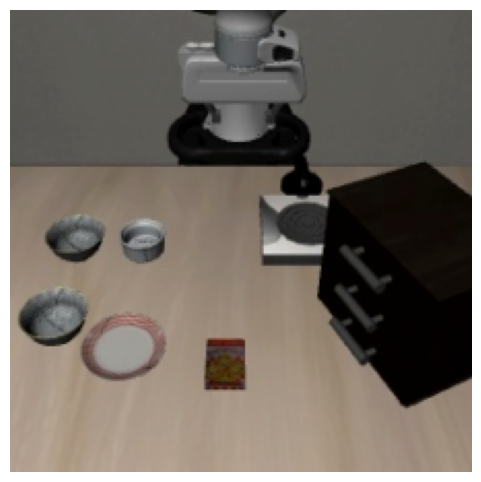

In [3]:
sample = train_dataset[0]

plt.figure(figsize=(6, 6))
plt.imshow(sample["image"].permute(1, 2, 0))
plt.axis("off")
plt.show()

#  Train

In [4]:
train_model(train_dataset, val_dataset)


Dataset sizes:
Train: 41935
Val:   5505


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Total parameters:     78,697,479
Trainable parameters: 15,333,831
Trainable ratio:      19.48%


Epoch 1/50:   0%|          | 0/656 [00:00<?, ?it/s]

Epoch 1/50 | Train Loss: 0.135386 | Val Loss: 0.103271 ← BEST


Epoch 2/50:   0%|          | 0/656 [00:00<?, ?it/s]

... (93 outputs left out)

Epoch 49/50:   0%|          | 0/656 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.028294 | Val Loss: 0.041238


Epoch 50/50:   0%|          | 0/656 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.028091 | Val Loss: 0.042205

Best validation loss: 0.038405
Best model saved to: results/best_minivla.pt
Training curves saved to: results/training_curves.png


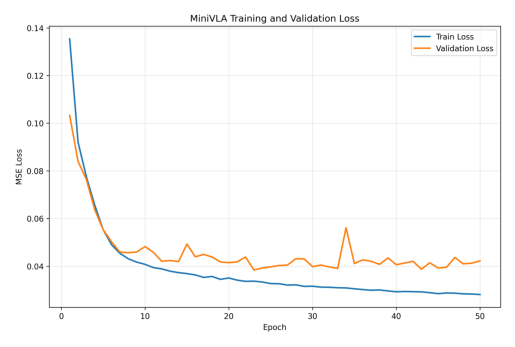

In [8]:
image = Image.open("results/training_curves.png")

plt.imshow(image)
plt.axis("off")
plt.show()

# Evaluation

In [9]:
evaluate_model(test_dataset)


Test dataset:
Test: 5530


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loaded checkpoint: results/best_minivla.pt

--------------------------------------------------
FINAL TEST RESULTS
--------------------------------------------------
Test samples: 5530
Test MSE:     0.038973
Test MAE:     0.094021


# inference

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loaded checkpoint: results/best_minivla.pt

--------------------------------------------------
INFERENCE RESULT
--------------------------------------------------
Sample index: 0

Instruction:
pick up the black bowl between the plate and the ramekin and place it on the plate

Ground Truth Action:
[ 0.0777  0.0884  0.1018 -0.0086  0.0332 -0.     -1.    ]

Predicted Action:
[ 0.2816  0.1595  0.1261 -0.0049  0.0185 -0.001  -0.9495]

Action MSE: 0.007143
Action MAE: 0.052749

--------------------------------------------------
GROUND TRUTH — HUMAN READABLE
--------------------------------------------------
X movement       : +0.0777
Y movement       : +0.0884
Z movement       : +0.1018
Rotation X       : -0.0086
Rotation Y       : +0.0332
Rotation Z       : -0.0000
Gripper          : -1.0000 → CLOSED

--------------------------------------------------
PREDICTION — HUMAN READABLE
--------------------------------------------------
X movement       : +0.2816
Y movement       : +0.1595
Z moveme

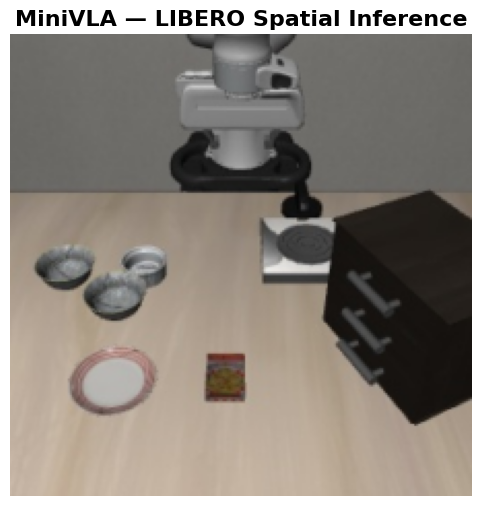

In [10]:
image_np = run_inference(test_dataset, sample_index=0)


# Display Only the Original Image

plt.figure(figsize=(8, 6))
plt.imshow(image_np)
plt.axis("off")
plt.title("MiniVLA — LIBERO Spatial Inference", fontsize=16, fontweight="bold")
plt.show()